Two Traders, Two Strategies: Brownian Bridge Prices

Axes of Variation

1. **Number of traders:** 2.
2. **Strategy switching:** Deterministic weekly switching. Each trader selects the strategy with the higher return over the previous calendar week's trading days.
3. **Number of strategies:** 2. One-day momentum and one-day contrarian.
4. **Firm policy:** Evaluate returns only. No quorum, capital reallocation, hiring, or firing.
5. **Market history:** Nine generated Brownian bridge price paths using the same evaluation dates as our 2024 SPY dataset.
6. **Added market shocks:** No additional shocks. Random price movements come from the Brownian bridge.
7. **Strategy lookback:** Both trading strategies use the closing-price change between the two previous trading days. Strategy selection uses the previous week's strategy returns.
8. **Market-price independence:** The firm's trades do not affect market prices.

Brownian Bridge Price Generation

1. **Starting price:** Every path starts at $100 at the first evaluation day's open.
2. **Return scenarios:** The asset finishes at $85, $100, or $115, giving exactly -15%, 0%, or +15% from the first open to the final close.
3. **Fluctuation settings:** Each return scenario uses sigma values of 10, 20, and 30, labeled low, medium, and high. Sigma controls the size of random fluctuations around the line connecting the endpoints.
4. **Number of paths:** Generate one accepted path for each combination, giving nine paths total. These are individual examples rather than repeated trials for estimating average performance.
5. **Time scale:** Represent the evaluation year by $0 \leq t \leq 1$, where $t=0$ is the first evaluation day's open and $t=1$ is the final evaluation day's close.
6. **Brownian motion:** Begin with $W(0)=0$ and generate successive values using:

   $$
   W(t_{k+1}) = W(t_k) + \sqrt{\Delta t}Z_k,
   \qquad Z_k \sim N(0,1)
   $$

   - $W(t_k)$: Value of the Brownian motion at sampled time $t_k$
   - $k$: Index identifying a sampled time
   - $\Delta t = t_{k+1}-t_k$: Time between consecutive sampled points
   - $Z_k$: Independent random draw for step $k$
   - $N(0,1)$: Standard normal distribution, with mean 0 and variance 1
   - $\sim$: Means "is distributed as"

   Multiplying $Z_k$ by $\sqrt{\Delta t}$ gives each increment mean 0 and variance $\Delta t$. Adding these independent increments produces the sampled Brownian motion.

7. **Brownian bridge:** Transform the Brownian motion into a process that starts and ends at zero:

   $$
   B(t) = W(t) - tW(1)
   $$

   Here, $W(1)$ is the generated Brownian motion's final value. Subtracting $tW(1)$ gradually removes that terminal movement.

   $$
   B(0)=0,
   \qquad
   B(1)=W(1)-W(1)=0
   $$

   The path between the endpoints remains random.

8. **Price path:** Add the scaled bridge to a straight line connecting the chosen prices:

   $$
   P(t) = (1-t)P_0 + tP_1 + \sigma B(t)
   $$

   - $P(t)$: Generated asset price at normalized time $t$
   - $P_0$: Chosen starting price
   - $P_1$: Chosen ending price
   - $(1-t)P_0+tP_1$: Straight line joining the two endpoint prices
   - $\sigma$: Fluctuation scale, expressed in price units under our normalized time scale
   - $B(t)$: Standard Brownian bridge
   - $\sigma B(t)$: Random deviation from the straight line

   Because the bridge is zero at both endpoints:

   $$
   P(0)=P_0,
   \qquad
   P(1)=P_1
   $$

   For example, the +15% scenario has:

   $$
   P(t)=100+15t+\sigma B(t)
   $$

9. **Mean and variance:** Before positivity filtering, the price distribution across repeated generated paths at a fixed time $t$ has:

   $$
   \mathbb{E}[P(t)] = (1-t)P_0+tP_1
   $$

   $$
   \operatorname{Var}[P(t)] = \sigma^2t(1-t)
   $$

   - $\mathbb{E}[P(t)]$: Expected price, or theoretical mean across paths at time $t$
   - $\operatorname{Var}[P(t)]$: Variance across paths at time $t$, measured in squared price units
   - Standard deviation: Square root of the variance, measured in price units

   Variance is zero at the endpoints and largest at $t=1/2$, where it equals $\sigma^2/4$. The midpoint standard deviation is therefore $\sigma/2$. Sigma values of 10, 20, and 30 give midpoint standard deviations of $5, $10, and $15.

   These formulas describe variation across repeated paths at the same time, rather than the variance of prices over time within one path.

10. **Positive prices:** Reject the entire generated path if any sampled price is zero or negative. Generate another using the same random-number stream and record the rejection count. Accepted paths are therefore conditioned on positivity at the sampled points, so the unfiltered mean and variance formulas above need not hold exactly for the accepted distribution. This does not independently check crossings between sampled points.
11. **Trading dates:** Copy the evaluation dates from the saved SPY dataset. Use its final two trading dates before evaluation for warm-up observations.
12. **Opening and closing prices:** For $n$ evaluation trading days, generate $2n$ price points. Order them as the first day's open, first day's close, second day's open, second day's close, and so on.
13. **Time spacing:** Space the $2n$ points equally over the normalized year:

   $$
   \Delta t = \frac{1}{2n-1},
   \qquad
   t_k = k\Delta t,
   \qquad
   k=0,\ldots,2n-1
   $$

   There are $2n-1$ intervals between the $2n$ points. Open-to-close and close-to-next-open movements receive equal simulation intervals rather than actual clock-hour durations.

14. **Warm-up prices:** Set both earlier closing prices to $100. The first evaluation day's signal is therefore unchanged, and both traders initially remain in cash. These observations are outside the bridge's evaluation interval.
15. **Information restriction:** The generator sets the endpoint, but traders only use the past observations permitted by their trading and switching rules.
16. **Reproducibility:** Each path has its own recorded random seed, which initializes the pseudorandom-number generator so the same path can be reproduced. The displayed bridge paths are the exact paths used by the trading simulation.

Trading Strategy - One-Day Momentum

1. **Basic idea:** The trader follows the direction of the previous trading day's closing-price change.
2. **Positive price change:** If the previous close was higher than the close before it, buy using all available cash or hold if already invested.
3. **Negative price change:** If the previous close was lower than the close before it, sell all owned shares or remain in cash.
4. **No price change:** If the two closes were equal, keep the current position.
5. **Execution timing:** Use the two most recent completed closing prices to decide what to do at the next trading day's open. Execute trades at that opening price.
6. **Information restriction:** Today's closing price cannot influence today's opening trade.
7. **Holding period:** Positions remain in place, including overnight, until a later trading decision changes them.

Trading Strategy - One-Day Contrarian

1. **Basic idea:** The trader acts against the direction of the previous trading day's closing-price change.
2. **Positive price change:** If the previous close was higher than the close before it, sell all owned shares or remain in cash.
3. **Negative price change:** If the previous close was lower than the close before it, buy using all available cash or hold if already invested.
4. **No price change:** If the two closes were equal, keep the current position.
5. **Execution timing:** Use the two most recent completed closing prices to decide what to do at the next trading day's open. Execute trades at that opening price.
6. **Information restriction:** Today's closing price cannot influence today's opening trade.
7. **Holding period:** Positions remain in place, including overnight, until a later trading decision changes them.

Strategy Evaluation and Switching

1. **Starting strategies:** Trader 1 starts with momentum. Trader 2 starts with contrarian.
2. **Review timing:** Review before the first trading day's open in each new calendar week. If Monday is a holiday, review on the next available trading day.
3. **Review period:** Compare strategy returns over the previous calendar week's available trading days.
4. **Strategy tracking:** Evaluate both strategies throughout each week, even when neither trader is using one of them.
5. **Equal starting conditions:** Each strategy's hypothetical evaluation account starts each week with $5,000 in cash and zero shares.
6. **Strategy return:** Calculate each hypothetical account's percentage return from its starting cash to its value at the week's final close. These accounts measure strategy performance and add no money to the firm.
7. **Selection rule:** Both traders select the strategy with the higher weekly percentage return. If both strategies lose money, select the one with the smaller loss.
8. **Tie rule:** If the strategy returns are equal, each trader keeps their current strategy.
9. **Switching behavior:** Both traders decide simultaneously. Their selected strategies determine their actions at that day's open.
10. **Portfolio continuity:** Switching does not reset a trader's cash or shares and does not automatically force a sale.
11. **First review:** Keep the assigned starting strategies during the first evaluation week. Review that week's performance at the start of the following week.
12. **Holiday handling:** Detect a new calendar week by comparing the current trading date with the previous trading date. A shortened week uses only its available trading days.

Portfolio and Firm Rules

1. **Starting capital:** The firm begins each path with $10,000, divided equally between its two traders.
2. **Starting position:** Each trader begins with $5,000 in cash and zero shares.
3. **Capital allocation:** Traders keep separate portfolios. No money is transferred between them or rebalanced at weekly reviews.
4. **Position size:** Purchases use all available cash. Sales liquidate the entire position. Fractional shares are allowed.
5. **Allowed actions:** Buy, sell, or hold. Traders can sell only shares they already own.
6. **Restrictions:** No short selling, borrowing, or leverage.
7. **Costs and income:** Transaction costs, slippage, dividends, and cash interest are excluded.
8. **Price data:** Use the generated opening and closing prices. Historical SPY prices are not traded.
9. **Firm behavior:** The firm observes and evaluates trader performance without influencing trading decisions.
10. **Final position:** Remaining shares are valued at the final closing price without forcing a sale.

Performance Evaluation

1. **Trader portfolio value:** At each trading day's close, add the trader's cash to the closing market value of their shares.

   $$
   V_i(t) = C_i(t) + Q_i(t)P(t)
   $$

   - $V_i(t)$: Trader $i$'s portfolio value at time $t$
   - $C_i(t)$: Trader $i$'s cash at time $t$
   - $Q_i(t)$: Trader $i$'s shares at time $t$
   - $P(t)$: Generated closing price at time $t$

2. **Trader cumulative return:** Divide the gain or loss by the trader's initial capital, then multiply by 100.

   $$
   R_i(t) =
   \frac{V_i(t) - V_i(0)}{V_i(0)}
   \times 100
   $$

   For this model, $V_i(0) = 5{,}000$ for each trader.

3. **Firm portfolio value:** Add the portfolio values of both traders.

   $$
   V_{\text{firm}}(t) = \sum_{i=1}^{2} V_i(t)
   $$

   Trader portfolios may have different values even when both traders use the same strategy.

4. **Firm cumulative return:** Divide the firm's total gain or loss by its initial $10,000, then multiply by 100.

   $$
   R_{\text{firm}}(t) =
   \frac{V_{\text{firm}}(t) - 10{,}000}{10{,}000}
   \times 100
   $$

Tidy Tables and Summary Statistics

1. **Daily results:** One row per path, date, and portfolio. Portfolios include the firm, both actual traders, and two fixed-strategy comparison portfolios.
2. **Fixed strategies:** Each comparison portfolio starts with $5,000 and follows one strategy continuously throughout the year. These portfolios do not reset weekly and contribute no money to the firm.
3. **Run summaries:** One row per path and portfolio, reporting final value, return, return volatility, maximum drawdown, purchases, sales, and strategy switches.
4. **Monthly summaries:** One row per path, portfolio, and month. Monthly returns use the previous month's final value, or initial capital for the first month.
5. **Daily return volatility:** Sample standard deviation of daily simple percentage returns. The first daily return is measured against initial capital.
6. **Annualized volatility:** Daily return volatility multiplied by the square root of the number of evaluation trading days. This is a conventional scaling statistic, not a guarantee about future variability.
7. **Maximum drawdown:** Largest percentage decline from a previous portfolio peak, including initial capital as the first observation.
8. **Trade counts:** Purchases and sales count executed trades. Firm counts sum the two traders' executions.
9. **Strategy switches:** Count actual changes in selected strategy. The initial strategy assignment is not a switch.
10. **Parameters:** Tables identify the path, scenario return, fluctuation scale, seed, starting price, capital, trading frequency, and review frequency.
11. **Weekly scores:** Retain them internally for model validation without exporting a weekly table.

In [1]:
%pip install numpy pandas matplotlib


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

STARTING_CASH = 10_000.0
START_PRICE = 100.0
START_DATE = "2024-01-01"
END_DATE = "2024-12-31"

RETURN_SCENARIOS = [-0.15, 0.0, 0.15]
FLUCTUATION_LEVELS = [("Low", 10), ("Medium", 20), ("High", 30)]
BASE_SEED = 42

calendar_file = Path("data/spy_2024_with_warmup.csv")
output_folder = Path("data/brownian_two_trader")
output_folder.mkdir(parents=True, exist_ok=True)

# Copy dates from our saved baseline without using its prices
if not calendar_file.exists():
    raise FileNotFoundError(
        "Place this notebook beside the existing notebooks so "
        "data/spy_2024_with_warmup.csv is available"
    )

calendar_data = pd.read_csv(
    calendar_file, index_col="Date", parse_dates=True
)

if (
    not calendar_data.index.is_unique
    or not calendar_data.index.is_monotonic_increasing
):
    raise ValueError("The saved calendar must have unique dates in order")

trading_dates = calendar_data.loc[START_DATE:END_DATE].index

if len(trading_dates) < 2:
    raise ValueError("The saved file must contain the 2024 evaluation dates")

warmup_dates = calendar_data.index[
    calendar_data.index < trading_dates[0]
][-2:]

if len(warmup_dates) != 2:
    raise ValueError("The saved file must include two earlier trading dates")

NUMBER_OF_DAYS = len(trading_dates)

print("Evaluation trading days:", NUMBER_OF_DAYS)
print("First trading date:", trading_dates[0].date())
print("Final trading date:", trading_dates[-1].date())

Evaluation trading days: 252
First trading date: 2024-01-02
Final trading date: 2024-12-31


In [3]:
def make_bridge(start_price, end_price, sigma, seed, number_of_days):
    rng = np.random.default_rng(seed)
    time = np.linspace(0, 1, 2 * number_of_days)
    time_step = time[1] - time[0]

    for rejected in range(10_000):
        # Generate Brownian motion using independent normal increments
        increments = rng.normal(
            loc=0,
            scale=np.sqrt(time_step),
            size=len(time) - 1,
        )
        motion = np.concatenate(([0.0], np.cumsum(increments)))

        # Make the random component start and end at zero
        bridge = motion - time * motion[-1]

        # Add fluctuations around the line joining our chosen endpoints
        path = (
            (1 - time) * start_price
            + time * end_price
            + sigma * bridge
        )

        path[0] = start_price
        path[-1] = end_price

        # Reject an entire path if any sampled price is invalid
        if np.isfinite(path).all() and (path > 0).all():
            return time, path, rejected

    raise RuntimeError("Could not generate a positive price path")


price_paths = {}
bridge_points = {}
parameter_records = []

for scenario_return in RETURN_SCENARIOS:
    for level, sigma in FLUCTUATION_LEVELS:
        path_number = len(parameter_records) + 1
        path_id = f"BB{path_number:02d}"
        seed = BASE_SEED + path_number - 1
        ending_price = START_PRICE * (1 + scenario_return)

        time, path, rejected = make_bridge(
            START_PRICE,
            ending_price,
            sigma,
            seed,
            NUMBER_OF_DAYS,
        )

        # Consecutive points alternate between opening and closing prices
        evaluation_prices = pd.DataFrame(
            {
                "Open": path[::2],
                "Close": path[1::2],
            },
            index=trading_dates,
        )

        # Equal earlier closes give both strategies a neutral first signal
        warmup = pd.DataFrame(
            {"Open": START_PRICE, "Close": START_PRICE},
            index=warmup_dates,
        )

        path_prices = pd.concat([warmup, evaluation_prices])
        path_prices.index.name = "Date"

        price_paths[path_id] = path_prices
        bridge_points[path_id] = (time, path)

        parameter_records.append({
            "PathID": path_id,
            "ScenarioReturnPct": 100 * scenario_return,
            "VarianceLevel": level,
            "Sigma": sigma,
            "DiffusionVariance": sigma ** 2,
            "UnconditionedMidpointVariance": sigma ** 2 / 4,
            "Seed": seed,
            "RejectedPaths": rejected,
            "StartPrice": START_PRICE,
            "EndPrice": ending_price,
            "TradingDays": NUMBER_OF_DAYS,
            "TradingFrequencyDays": 1,
            "LookbackDays": 1,
            "ReviewFrequency": "Weekly",
            "FirmStartingCapital": STARTING_CASH,
            "TraderStartingCapital": STARTING_CASH / 2,
            "NumberOfTraders": 2,
            "NumberOfStrategies": 2,
            "BridgeType": "Price Brownian bridge",
            "WarmupClose": START_PRICE,
            "EvaluationStart": str(trading_dates[0].date()),
            "EvaluationEnd": str(trading_dates[-1].date()),
        })

parameters = pd.DataFrame(parameter_records)

display(parameters[[
    "PathID", "ScenarioReturnPct", "VarianceLevel",
    "Sigma", "StartPrice", "EndPrice", "Seed", "RejectedPaths",
]])

,PathID,ScenarioReturnPct,VarianceLevel,Sigma,StartPrice,EndPrice,Seed,RejectedPaths
0,BB01,-15.0,Low,10,100.0,85.0,42,0
1,BB02,-15.0,Medium,20,100.0,85.0,43,0
2,BB03,-15.0,High,30,100.0,85.0,44,0
3,BB04,0.0,Low,10,100.0,100.0,45,0
4,BB05,0.0,Medium,20,100.0,100.0,46,0
5,BB06,0.0,High,30,100.0,100.0,47,0
6,BB07,15.0,Low,10,100.0,115.0,48,0
7,BB08,15.0,Medium,20,100.0,115.0,49,0
8,BB09,15.0,High,30,100.0,115.0,50,0


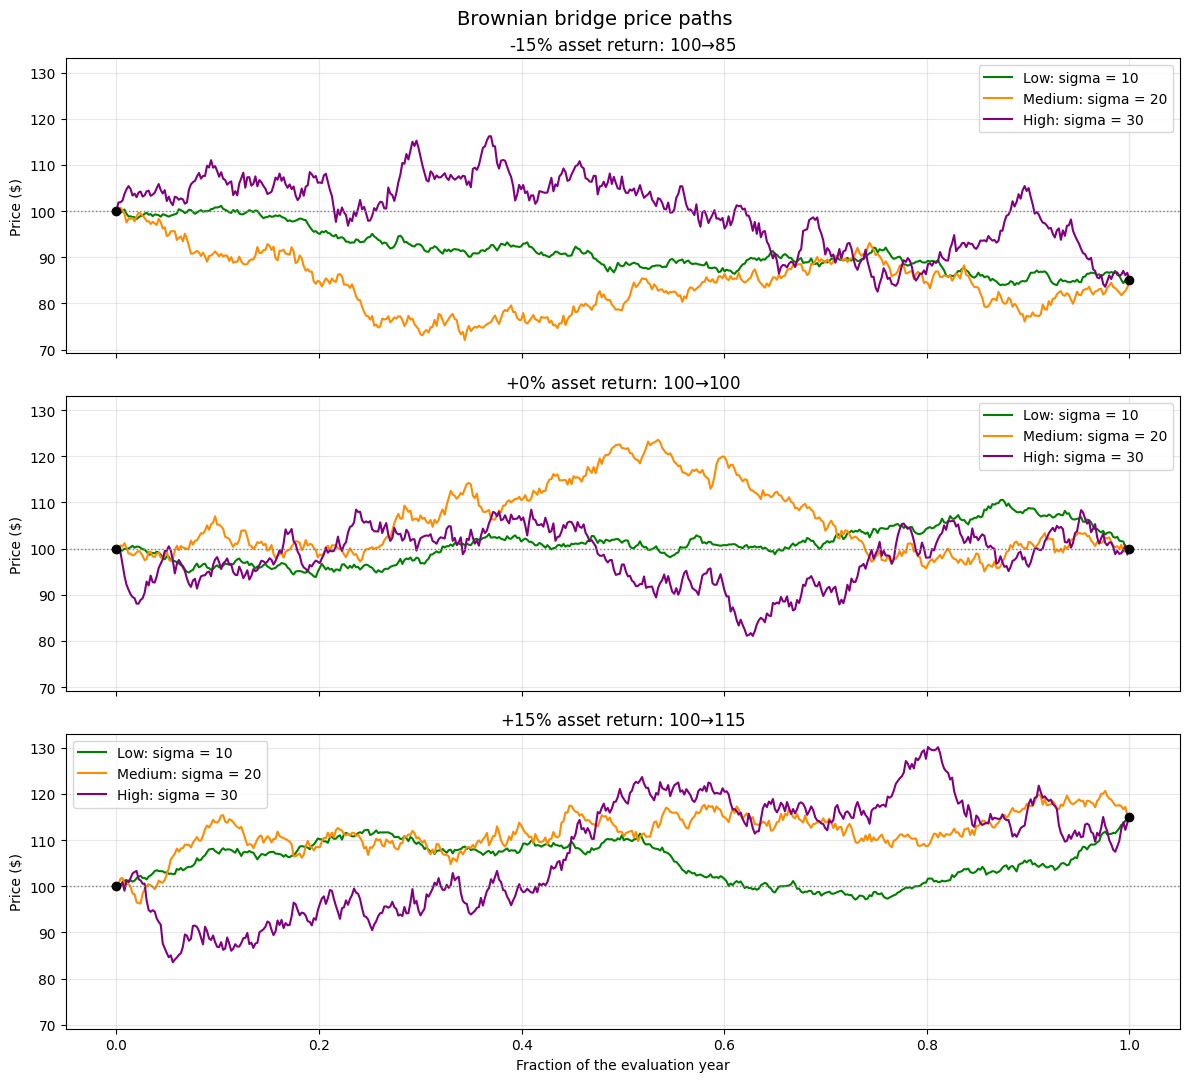

In [4]:
colors = {
    "Low": "green",
    "Medium": "darkorange",
    "High": "purple",
}

fig, axes = plt.subplots(
    3, 1, figsize=(12, 11), sharex=True, sharey=True
)

for ax, scenario_return in zip(axes, RETURN_SCENARIOS):
    scenario_paths = parameters[
        np.isclose(parameters["ScenarioReturnPct"], 100 * scenario_return)
    ]

    for _, settings in scenario_paths.iterrows():
        time, path = bridge_points[settings["PathID"]]
        level = settings["VarianceLevel"]

        ax.plot(
            time,
            path,
            color=colors[level],
            label=f"{level}: sigma = {settings['Sigma']}",
        )

    ending_price = START_PRICE * (1 + scenario_return)

    ax.scatter(
        [0, 1],
        [START_PRICE, ending_price],
        color="black",
        zorder=5,
    )

    ax.axhline(START_PRICE, color="gray", linestyle=":", linewidth=1)
    ax.set_title(
        f"{scenario_return:+.0%} asset return: "
        f"${START_PRICE:.0f} → ${ending_price:.0f}"
    )
    ax.set_ylabel("Price ($)")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Fraction of the evaluation year")
fig.suptitle("Brownian bridge price paths", fontsize=14)

plt.tight_layout()
plt.show()

In [5]:
def execute_trade(cash, shares, signal, opening_price):
    # Buy using only our available cash
    if signal > 0 and cash > 0:
        return 0.0, cash / opening_price, "BUY"

    # Sell only the shares we already own
    if signal < 0 and shares > 0:
        return shares * opening_price, 0.0, "SELL"

    return cash, shares, "HOLD"


def run_model(prices, starting_cash, start, end):
    if starting_cash <= 0:
        raise ValueError("Starting cash must be positive")

    if (
        prices.empty
        or not prices.index.is_unique
        or not prices.index.is_monotonic_increasing
    ):
        raise ValueError("Data must have unique dates in order")

    if (
        not np.isfinite(prices[["Open", "Close"]].to_numpy()).all()
        or (prices[["Open", "Close"]] <= 0).any().any()
    ):
        raise ValueError("Opening and closing prices must be finite and positive")

    # Today's decision uses only the two previous completed closes
    changes = prices["Close"].shift(1) - prices["Close"].shift(2)
    days = prices.loc[start:end]

    if days.empty or changes.loc[days.index].isna().any():
        raise ValueError("We need evaluation data and two earlier closes")

    allocation = starting_cash / 2

    traders = [
        {
            "Trader": "Trader 1",
            "Strategy": "Momentum",
            "Cash": allocation,
            "Shares": 0.0,
        },
        {
            "Trader": "Trader 2",
            "Strategy": "Contrarian",
            "Cash": allocation,
            "Shares": 0.0,
        },
    ]

    records = []
    reviews = []
    current_week = None

    for date, day in days.iterrows():
        week = date.to_period("W-SUN")

        if week != current_week:
            # Review the finished week before doing anything with today's prices
            if current_week is not None:
                strategy_returns = {
                    name: 100 * (account["Value"] - allocation) / allocation
                    for name, account in scores.items()
                }

                momentum_return = strategy_returns["Momentum"]
                contrarian_return = strategy_returns["Contrarian"]

                if momentum_return > contrarian_return:
                    winner = "Momentum"
                elif contrarian_return > momentum_return:
                    winner = "Contrarian"
                else:
                    winner = "Tie"

                # Switching changes the decision rule without resetting holdings
                for trader in traders:
                    if winner != "Tie":
                        trader["Strategy"] = winner

                reviews.append({
                    "ReviewDate": date,
                    "PeriodStart": week_start,
                    "PeriodEnd": previous_date,
                    "MomentumReturnPct": momentum_return,
                    "ContrarianReturnPct": contrarian_return,
                    "Winner": winner,
                    "Trader1Strategy": traders[0]["Strategy"],
                    "Trader2Strategy": traders[1]["Strategy"],
                })

            # Only the hypothetical scoring accounts restart each week
            scores = {
                name: {"Cash": allocation, "Shares": 0.0}
                for name in ["Momentum", "Contrarian"]
            }

            current_week = week
            week_start = date

        change = changes.loc[date]
        momentum_signal = 1 if change > 0 else -1 if change < 0 else 0

        signals = {
            "Momentum": momentum_signal,
            "Contrarian": -momentum_signal,
        }

        for trader in traders:
            signal = signals[trader["Strategy"]]

            trader["Cash"], trader["Shares"], trader["Action"] = execute_trade(
                trader["Cash"],
                trader["Shares"],
                signal,
                day["Open"],
            )

            trader["Value"] = (
                trader["Cash"] + trader["Shares"] * day["Close"]
            )

        firm_value = sum(trader["Value"] for trader in traders)

        for trader in traders:
            records.append({
                "Date": date,
                "Trader": trader["Trader"],
                "Strategy": trader["Strategy"],
                "Open": day["Open"],
                "Close": day["Close"],
                "Signal": signals[trader["Strategy"]],
                "Action": trader["Action"],
                "Cash": trader["Cash"],
                "Shares": trader["Shares"],
                "TraderValue": trader["Value"],
                "TraderReturnPct": (
                    100 * (trader["Value"] - allocation) / allocation
                ),
                "FirmValue": firm_value,
                "FirmReturnPct": (
                    100 * (firm_value - starting_cash) / starting_cash
                ),
            })

        # Evaluate both strategies even when nobody currently follows one
        for name, account in scores.items():
            account["Cash"], account["Shares"], _ = execute_trade(
                account["Cash"],
                account["Shares"],
                signals[name],
                day["Open"],
            )

            account["Value"] = (
                account["Cash"] + account["Shares"] * day["Close"]
            )

        previous_date = date

    return pd.DataFrame(records), pd.DataFrame(reviews)

In [6]:
example = pd.DataFrame({
    "Open": [
        100, 100, 100, 111, 120, 105,
        102, 100, 125, 110, 110, 100,
    ],
    "Close": [
        100, 102, 110, 105, 100, 100,
        110, 120, 115, 110, 110, 105,
    ],
}, index=pd.to_datetime([
    "2023-12-28", "2023-12-29",
    "2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05",
    "2024-01-08", "2024-01-09", "2024-01-10", "2024-01-11",
    "2024-01-12", "2024-01-16",
]))

check, check_reviews = run_model(
    example, STARTING_CASH, START_DATE, END_DATE
)

# Check the Monday review and the Tuesday review after a Monday holiday
assert check_reviews["ReviewDate"].tolist() == list(
    pd.to_datetime(["2024-01-08", "2024-01-16"])
)
assert check_reviews["Winner"].tolist() == ["Momentum", "Momentum"]

assert round(check_reviews.iloc[0]["MomentumReturnPct"], 6) == 20.0
assert round(check_reviews.iloc[0]["ContrarianReturnPct"], 6) == -16.666667

trader_1 = check[check["Trader"] == "Trader 1"]

assert trader_1["TraderValue"].round(2).tolist() == [
    5500, 5250, 6000, 6000, 6000,
    7200, 6900, 6600, 6600, 6600,
]

# Changing today's close must not change today's opening decision
changed = example.copy()
changed.loc["2024-01-08", "Close"] = 50

changed_check, changed_reviews = run_model(
    changed, STARTING_CASH, START_DATE, END_DATE
)

assert check_reviews.iloc[0].equals(changed_reviews.iloc[0])
assert check.loc[
    check["Date"] == "2024-01-08", "Shares"
].tolist() == changed_check.loc[
    changed_check["Date"] == "2024-01-08", "Shares"
].tolist()

# A tie keeps the assigned strategies
flat = example.copy()
flat["Open"] = 100
flat["Close"] = 100

flat_check, flat_reviews = run_model(
    flat, STARTING_CASH, START_DATE, END_DATE
)

assert flat_reviews["Winner"].eq("Tie").all()
assert flat_check.loc[
    flat_check["Trader"] == "Trader 1", "Strategy"
].eq("Momentum").all()
assert flat_check.loc[
    flat_check["Trader"] == "Trader 2", "Strategy"
].eq("Contrarian").all()

# An unused strategy can become the winner at the next review
unused = example.copy()
unused.loc["2024-01-11", "Open"] = 80

unused_check, unused_reviews = run_model(
    unused, STARTING_CASH, START_DATE, END_DATE
)

assert unused_reviews["Winner"].tolist() == ["Momentum", "Contrarian"]
assert unused_check.loc[
    unused_check["Date"] == "2024-01-16", "Strategy"
].eq("Contrarian").all()

print("Original model checks passed")

Original model checks passed


In [7]:
def run_fixed_strategy(prices, name):
    cash = STARTING_CASH / 2
    shares = 0.0
    records = []

    changes = prices["Close"].shift(1) - prices["Close"].shift(2)

    for date, day in prices.loc[START_DATE:END_DATE].iterrows():
        change = changes.loc[date]
        signal = 1 if change > 0 else -1 if change < 0 else 0

        if name == "Contrarian":
            signal = -signal

        cash, shares, action = execute_trade(
            cash, shares, signal, day["Open"]
        )

        value = cash + shares * day["Close"]

        records.append({
            "Date": date,
            "Entity": f"Fixed {name.lower()}",
            "Strategy": name,
            "Open": day["Open"],
            "Close": day["Close"],
            "Signal": signal,
            "Action": action,
            "Cash": cash,
            "Shares": shares,
            "Value": value,
            "ReturnPct": 100 * (value / (STARTING_CASH / 2) - 1),
            "InitialCapital": STARTING_CASH / 2,
            "BuyCount": int(action == "BUY"),
            "SellCount": int(action == "SELL"),
            "SwitchCount": 0,
        })

    return pd.DataFrame(records)

In [16]:
daily_frames = []
reviews_by_path = {}

for _, settings in parameters.iterrows():
    path_id = settings["PathID"]
    path_prices = price_paths[path_id]

    results, reviews = run_model(
        path_prices, STARTING_CASH, START_DATE, END_DATE
    )
    reviews_by_path[path_id] = reviews

    # Standardize the actual trader records for our tidy table
    traders = results.rename(columns={
        "Trader": "Entity",
        "TraderValue": "Value",
        "TraderReturnPct": "ReturnPct",
    }).drop(columns=["FirmValue", "FirmReturnPct"])

    traders["InitialCapital"] = STARTING_CASH / 2
    traders["BuyCount"] = traders["Action"].eq("BUY").astype(int)
    traders["SellCount"] = traders["Action"].eq("SELL").astype(int)

    # Count changes in strategy without counting the initial assignment
    traders["SwitchCount"] = traders.groupby("Entity")["Strategy"].transform(
        lambda s: s.ne(s.shift()) & s.shift().notna()
    ).astype(int)

    # Combine the actual portfolios into one firm observation per date
    firm = results.groupby("Date", sort=True).agg(
        Open=("Open", "first"),
        Close=("Close", "first"),
        Cash=("Cash", "sum"),
        Shares=("Shares", "sum"),
        Value=("FirmValue", "first"),
        ReturnPct=("FirmReturnPct", "first"),
    ).reset_index()

    counts = traders.groupby("Date")[[
        "BuyCount", "SellCount", "SwitchCount"
    ]].sum().reset_index()

    firm = firm.merge(counts, on="Date", validate="one_to_one")
    firm["Entity"] = "Firm"
    firm["Strategy"] = "Combined"
    firm["Signal"] = np.nan
    firm["Action"] = pd.NA
    firm["InitialCapital"] = STARTING_CASH

    fixed = pd.concat([
        run_fixed_strategy(path_prices, "Momentum"),
        run_fixed_strategy(path_prices, "Contrarian"),
    ], ignore_index=True)

    combined = pd.concat(
        [traders, firm, fixed], ignore_index=True
    )

    # Label every observation with the settings that produced it
    for column, value in settings.items():
        combined[column] = value

    daily_frames.append(combined)

daily_results = pd.concat(
    daily_frames, ignore_index=True
).sort_values(["PathID", "Entity", "Date"]).reset_index(drop=True)

previous_values = daily_results.groupby(
    ["PathID", "Entity"]
)["Value"].shift()

previous_values = previous_values.fillna(daily_results["InitialCapital"])

daily_results["DailyReturnPct"] = 100 * (
    daily_results["Value"] / previous_values - 1
)

display(daily_results[[
    "PathID", "ScenarioReturnPct", "VarianceLevel", "Sigma",
    "Date", "Entity", "Strategy", "Action",
    "Cash", "Shares", "Value", "ReturnPct",
]].head(1000).round(4))

,PathID,ScenarioReturnPct,VarianceLevel,Sigma,Date,Entity,Strategy,Action,Cash,Shares,Value,ReturnPct
0,BB01,-15.0,Low,10,2024-01-02,Firm,Combined,NaN,10000.0000,0.0000,10000.0000,0.0000
1,BB01,-15.0,Low,10,2024-01-03,Firm,Combined,NaN,5000.0000,50.1900,10015.5208,0.1552
2,BB01,-15.0,Low,10,2024-01-04,Firm,Combined,NaN,5035.2962,49.8382,9990.6764,-0.0932
3,BB01,-15.0,Low,10,2024-01-05,Firm,Combined,NaN,5035.2962,49.8382,9962.0520,-0.3795
4,BB01,-15.0,Low,10,2024-01-08,Firm,Combined,NaN,9953.7602,0.0000,9953.7602,-0.4624
...,...,...,...,...,...,...,...,...,...,...,...,...
995,BB01,-15.0,Low,10,2024-12-12,Trader 1,Contrarian,HOLD,4723.6028,0.0000,4723.6028,-5.5279
996,BB01,-15.0,Low,10,2024-12-13,Trader 1,Contrarian,BUY,0.0000,55.1066,4727.6861,-5.4463
997,BB01,-15.0,Low,10,2024-12-16,Trader 1,Momentum,HOLD,0.0000,55.1066,4762.3542,-4.7529
998,BB01,-15.0,Low,10,2024-12-17,Trader 1,Momentum,HOLD,0.0000,55.1066,4772.4333,-4.5513


In [9]:
def period_statistics(frame, start_value):
    values = frame["Value"].to_numpy()

    # Include starting capital so an immediate loss counts toward drawdown
    curve = np.concatenate(([start_value], values))
    peaks = np.maximum.accumulate(curve)
    drawdowns = 100 * (1 - curve / peaks)

    previous = np.concatenate(([start_value], values[:-1]))
    daily_returns = values / previous - 1

    volatility = (
        100 * np.std(daily_returns, ddof=1)
        if len(daily_returns) > 1 else np.nan
    )

    return {
        "StartValue": start_value,
        "FinalValue": values[-1],
        "ReturnPct": 100 * (values[-1] / start_value - 1),
        "DailyReturnVolatilityPct": volatility,
        "AnnualizedVolatilityPct": volatility * np.sqrt(NUMBER_OF_DAYS),
        "MaxDrawdownPct": drawdowns.max(),
        "Purchases": int(frame["BuyCount"].sum()),
        "Sales": int(frame["SellCount"].sum()),
        "StrategySwitches": int(frame["SwitchCount"].sum()),
    }


summary_records = []
monthly_records = []
settings_lookup = parameters.set_index("PathID")

for (path_id, entity), frame in daily_results.groupby(
    ["PathID", "Entity"], sort=False
):
    settings = settings_lookup.loc[path_id].to_dict()
    settings["PathID"] = path_id

    initial_value = frame["InitialCapital"].iloc[0]

    summary_records.append({
        **settings,
        "Entity": entity,
        **period_statistics(frame, initial_value),
    })

    # Each month begins at the previous month's final portfolio value
    month_start_value = initial_value

    for month, month_frame in frame.groupby(frame["Date"].dt.to_period("M")):
        monthly_records.append({
            **settings,
            "Entity": entity,
            "Month": str(month),
            **period_statistics(month_frame, month_start_value),
        })

        month_start_value = month_frame["Value"].iloc[-1]

run_summary = pd.DataFrame(summary_records)
monthly_summary = pd.DataFrame(monthly_records)

summary_columns = [
    "PathID", "ScenarioReturnPct", "VarianceLevel", "Sigma", "Entity",
    "FinalValue", "ReturnPct", "DailyReturnVolatilityPct",
    "AnnualizedVolatilityPct", "MaxDrawdownPct",
    "Purchases", "Sales", "StrategySwitches",
]

display(run_summary[summary_columns].round(3))

print("Daily rows:", len(daily_results))
print("Run-summary rows:", len(run_summary))
print("Monthly-summary rows:", len(monthly_summary))

# Preview one path's monthly returns without changing the saved tidy format
monthly_preview = monthly_summary[
    monthly_summary["PathID"] == "BB01"
].pivot(index="Month", columns="Entity", values="ReturnPct")

display(monthly_preview.round(2))

,PathID,ScenarioReturnPct,VarianceLevel,Sigma,Entity,FinalValue,ReturnPct,DailyReturnVolatilityPct,AnnualizedVolatilityPct,MaxDrawdownPct,Purchases,Sales,StrategySwitches
0,BB01,-15.0,Low,10,Firm,9316.369,-6.836,0.480,7.620,7.903,126,124,51
1,BB01,-15.0,Low,10,Fixed contrarian,4741.321,-5.174,0.524,8.316,8.349,65,64,0
2,BB01,-15.0,Low,10,Fixed momentum,4498.905,-10.022,0.438,6.950,12.997,65,65,0
3,BB01,-15.0,Low,10,Trader 1,4712.860,-5.743,0.481,7.629,7.903,63,62,25
4,BB01,-15.0,Low,10,Trader 2,4603.509,-7.930,0.484,7.680,7.960,63,62,26
5,BB02,-15.0,Medium,20,Firm,7934.225,-20.658,1.096,17.405,23.692,146,146,57
6,BB02,-15.0,Medium,20,Fixed contrarian,4745.432,-5.091,1.051,16.682,15.350,71,71,0
7,BB02,-15.0,Medium,20,Fixed momentum,4444.853,-11.103,1.051,16.692,19.970,72,71,0
8,BB02,-15.0,Medium,20,Trader 1,3916.919,-21.662,1.107,17.574,24.653,73,73,29
9,BB02,-15.0,Medium,20,Trader 2,4017.305,-19.654,1.093,17.354,23.692,73,73,28


Daily rows: 11340
Run-summary rows: 45
Monthly-summary rows: 540


Entity,Firm,Fixed contrarian,Fixed momentum,Trader 1,Trader 2
Month,,,,,
2024-01,0.22,0.32,0.04,1.39,-0.96
2024-02,-1.09,1.25,-2.14,-1.09,-1.09
2024-03,-1.09,-4.34,-1.61,-1.09,-1.09
2024-04,1.77,1.71,-3.36,1.77,1.77
2024-05,-0.88,0.15,-1.03,-0.88,-0.88
2024-06,-1.91,-0.49,-4.07,-1.91,-1.91
2024-07,0.55,1.25,0.50,0.55,0.55
2024-08,2.09,1.16,0.65,2.09,2.09
2024-09,0.57,0.33,1.02,0.57,0.57


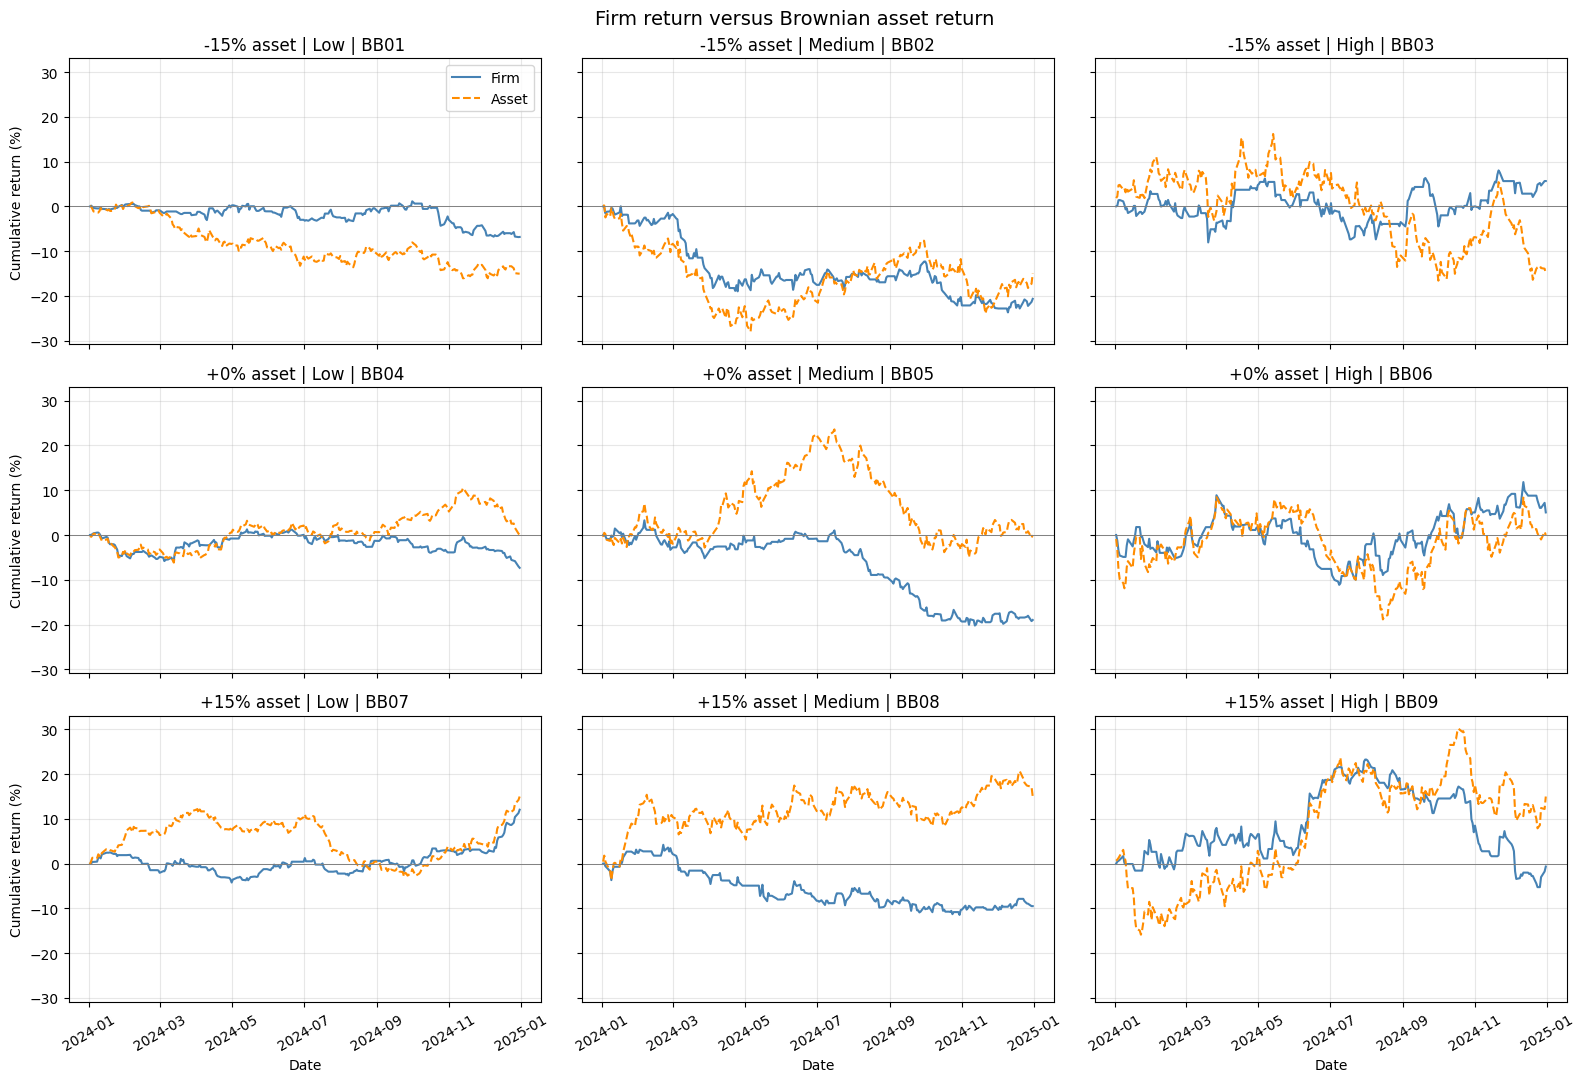

In [11]:
fig, axes = plt.subplots(
    3, 3, figsize=(16, 11), sharex=True, sharey=True
)

for ax, (_, settings) in zip(axes.flat, parameters.iterrows()):
    firm = daily_results[
        (daily_results["PathID"] == settings["PathID"])
        & (daily_results["Entity"] == "Firm")
    ]

    asset_return = 100 * (firm["Close"] / settings["StartPrice"] - 1)

    ax.plot(
        firm["Date"], firm["ReturnPct"],
        label="Firm", color="steelblue",
    )

    ax.plot(
        firm["Date"], asset_return,
        label="Asset", color="darkorange", linestyle="--",
    )

    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set_title(
        f"{settings['ScenarioReturnPct']:+.0f}% asset | "
        f"{settings['VarianceLevel']} | {settings['PathID']}"
    )
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelrotation=30)

axes[0, 0].legend()

for ax in axes[:, 0]:
    ax.set_ylabel("Cumulative return (%)")

for ax in axes[-1, :]:
    ax.set_xlabel("Date")

fig.suptitle("Firm return versus Brownian asset return", fontsize=14)
plt.tight_layout()
plt.show()

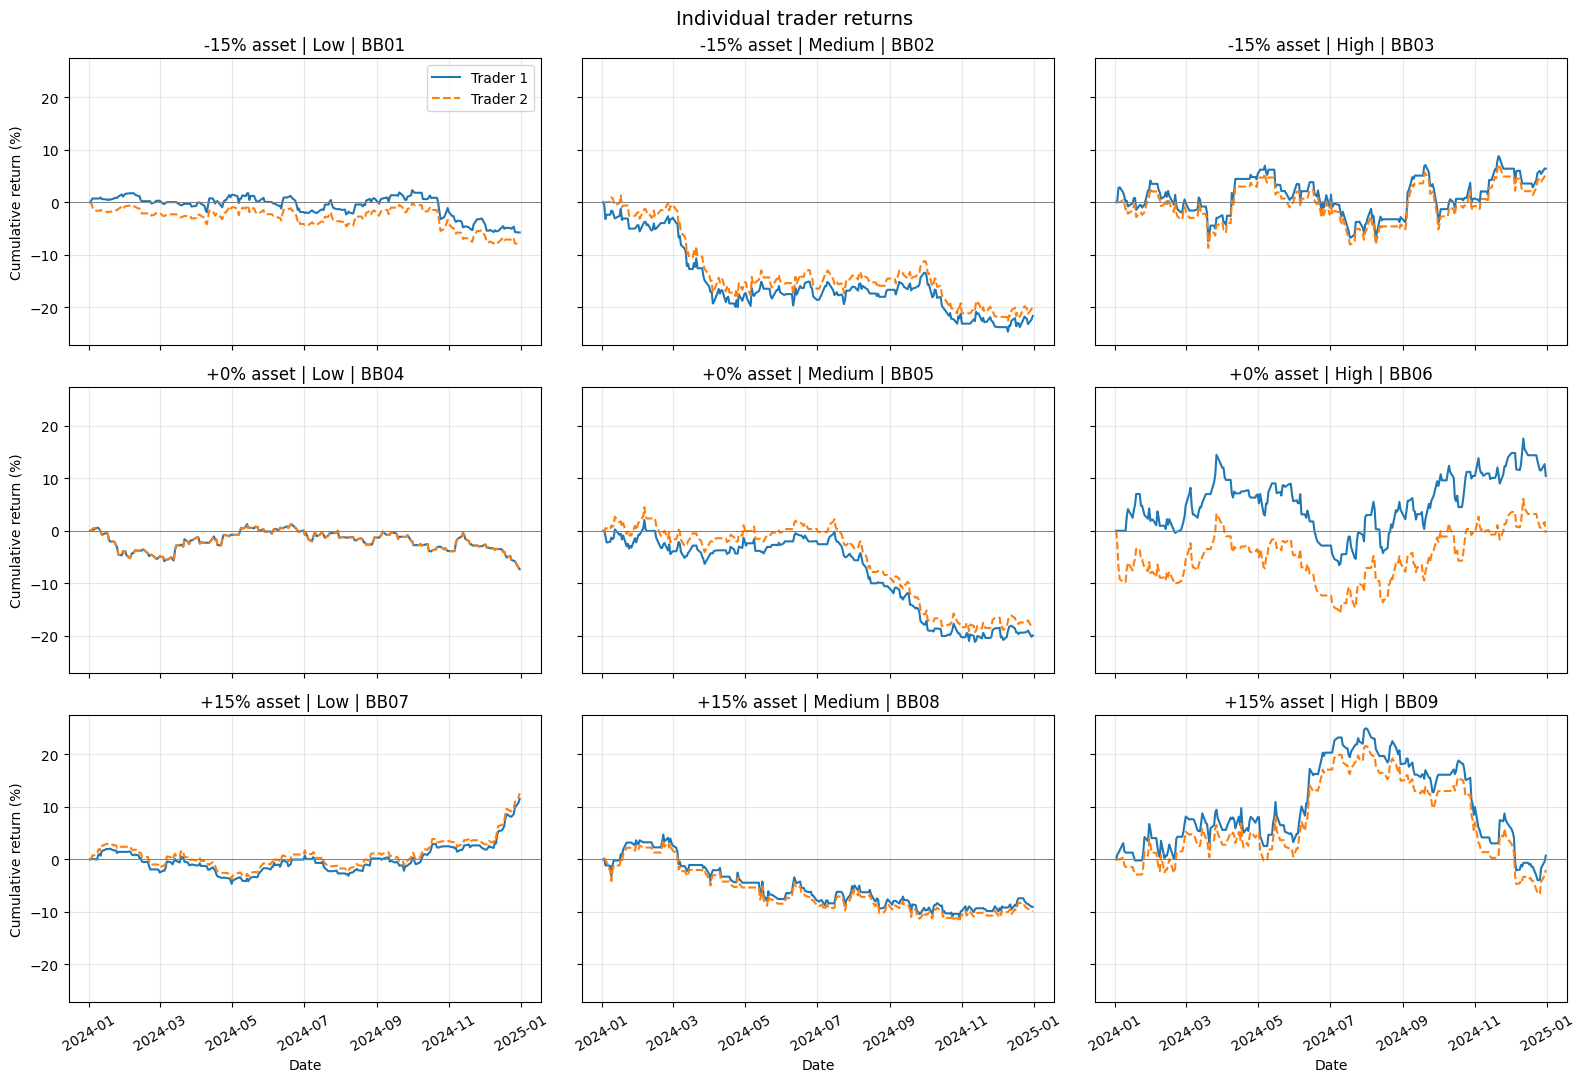

In [12]:
fig, axes = plt.subplots(
    3, 3, figsize=(16, 11), sharex=True, sharey=True
)

for ax, (_, settings) in zip(axes.flat, parameters.iterrows()):
    for trader, style in [("Trader 1", "-"), ("Trader 2", "--")]:
        frame = daily_results[
            (daily_results["PathID"] == settings["PathID"])
            & (daily_results["Entity"] == trader)
        ]

        ax.plot(
            frame["Date"],
            frame["ReturnPct"],
            linestyle=style,
            label=trader,
        )

    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set_title(
        f"{settings['ScenarioReturnPct']:+.0f}% asset | "
        f"{settings['VarianceLevel']} | {settings['PathID']}"
    )
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelrotation=30)

axes[0, 0].legend()

for ax in axes[:, 0]:
    ax.set_ylabel("Cumulative return (%)")

for ax in axes[-1, :]:
    ax.set_xlabel("Date")

fig.suptitle("Individual trader returns", fontsize=14)
plt.tight_layout()
plt.show()

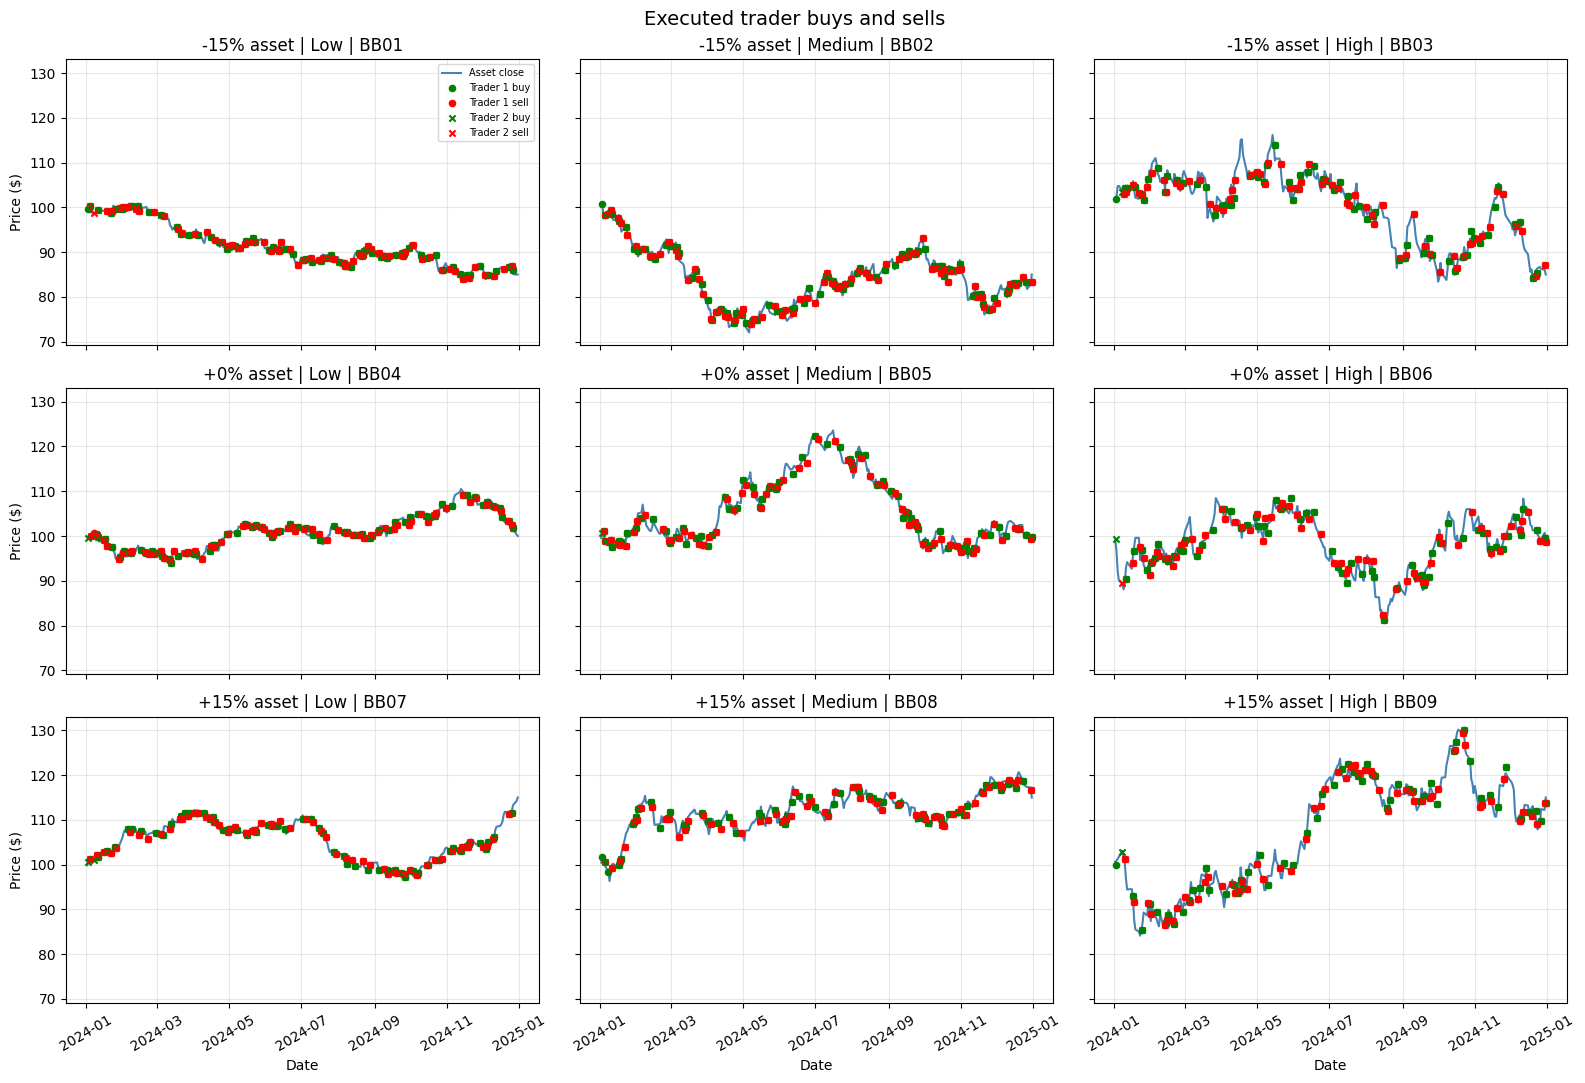

In [13]:
fig, axes = plt.subplots(
    3, 3, figsize=(16, 11), sharex=True, sharey=True
)

for ax, (_, settings) in zip(axes.flat, parameters.iterrows()):
    frame = daily_results[
        daily_results["PathID"] == settings["PathID"]
    ]

    firm = frame[frame["Entity"] == "Firm"]

    ax.plot(
        firm["Date"], firm["Close"],
        color="steelblue", label="Asset close",
    )

    # Marks show opening execution prices while the line shows closing prices
    for trader, marker in [("Trader 1", "o"), ("Trader 2", "x")]:
        for action, color in [("BUY", "green"), ("SELL", "red")]:
            trades = frame[
                (frame["Entity"] == trader)
                & (frame["Action"] == action)
            ]

            ax.scatter(
                trades["Date"],
                trades["Open"],
                color=color,
                marker=marker,
                s=20,
                label=f"{trader} {action.lower()}",
                zorder=3,
            )

    ax.set_title(
        f"{settings['ScenarioReturnPct']:+.0f}% asset | "
        f"{settings['VarianceLevel']} | {settings['PathID']}"
    )
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelrotation=30)

axes[0, 0].legend(fontsize=7)

for ax in axes[:, 0]:
    ax.set_ylabel("Price ($)")

for ax in axes[-1, :]:
    ax.set_xlabel("Date")

fig.suptitle("Executed trader buys and sells", fontsize=14)
plt.tight_layout()
plt.show()